<a href="https://colab.research.google.com/github/jeedderh01/Design-Envelope-FMECA-Feature-Mapping-Corrosion-Rate-Prediction-and-Remaining-Life/blob/main/case2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Implement the de Waard-Milliams corrosion rate model with unit tests.

In [4]:
import math

def calculate_fugacity_coefficient(temp_c: float, p_total_bar: float) -> float:
    """
    Calculates the CO2 fugacity coefficient (a) based on total pressure and temperature.
    log10(a) = P_total * (0.0031 - 1.4 / (T + 273.15))
    """
    t_kelvin = temp_c + 273.15
    log_a = p_total_bar * (0.0031 - (1.4 / t_kelvin))
    return 10.0 ** log_a

def calculate_co2_corrosion_rate(temp_c: float, p_co2_bar: float, p_total_bar: float = None) -> float:
    """
    Calculates the carbon steel CO2 corrosion rate using the de Waard-Milliams model.

    Parameters:
    - temp_c (float): Operating temperature in degrees Celsius (°C).
    - p_co2_bar (float): Partial pressure of CO2 in bar.
    - p_total_bar (float, optional): Total system pressure in bar. If None,
      assumed equal to p_co2_bar (ideal gas / low pressure assumption).

    Returns:
    - float: Corrosion rate in mm/year.
    """
    if temp_c < -273.15:
        raise ValueError("Temperature cannot be below absolute zero (-273.15 °C).")
    if p_co2_bar <= 0:
        raise ValueError("CO2 partial pressure must be greater than zero.")

    if p_total_bar is None:
        p_total_bar = p_co2_bar

    if p_total_bar < p_co2_bar:
        raise ValueError("Total pressure cannot be less than CO2 partial pressure.")

    # 1. Calculate CO2 fugacity (f_co2 = a * p_co2)
    fugacity_coeff = calculate_fugacity_coefficient(temp_c, p_total_bar)
    f_co2 = fugacity_coeff * p_co2_bar

    # Ensure fugacity is positive
    if f_co2 <= 0:
        raise ValueError("Calculated CO2 fugacity must be positive.")

    # 2. Base de Waard-Milliams nominal corrosion rate equation:
    # log10(v_cr) = 5.8 - (1710 / (T + 273.15)) + 0.67 * log10(f_co2)
    t_kelvin = temp_c + 273.15
    log_v_cr = 5.8 - (1710.0 / t_kelvin) + 0.67 * math.log10(f_co2)

    corrosion_rate = 10.0 ** log_v_cr
    return corrosion_rate

# unit test

In [7]:
import unittest

class TestDeWaardMilliamsModel(unittest.TestCase):

    def test_standard_conditions(self):
        """Test corrosion rate calculation under standard typical oilfield conditions."""
        # T = 60 °C, pCO2 = 0.5 bar, p_total = 10 bar
        cr = calculate_co2_corrosion_rate(temp_c=60.0, p_co2_bar=0.5, p_total_bar=10.0)
        # Expected value check (approximate expected baseline magnitude around 0.5 - 2.0 mm/yr)
        self.assertGreater(cr, 0.0)
        self.assertAlmostEqual(cr, 0.7725, places=3)

    def test_low_pressure_ideal_gas(self):
        """Test fallback behavior when total pressure isn't specified (defaults to p_co2)."""
        cr_default = calculate_co2_corrosion_rate(temp_c=40.0, p_co2_bar=1.0)
        cr_explicit = calculate_co2_corrosion_rate(temp_c=40.0, p_co2_bar=1.0, p_total_bar=1.0)
        self.assertEqual(cr_default, cr_explicit)

    def test_temperature_effect(self):
        """Verify that increasing temperature increases the uninhibited corrosion rate."""
        cr_low = calculate_co2_corrosion_rate(temp_c=30.0, p_co2_bar=1.0, p_total_bar=5.0)
        cr_high = calculate_co2_corrosion_rate(temp_c=70.0, p_co2_bar=1.0, p_total_bar=5.0)
        self.assertGreater(cr_high, cr_low)

    def test_partial_pressure_effect(self):
        """Verify that increasing CO2 partial pressure increases the corrosion rate."""
        cr_low_co2 = calculate_co2_corrosion_rate(temp_c=50.0, p_co2_bar=0.1, p_total_bar=2.0)
        cr_high_co2 = calculate_co2_corrosion_rate(temp_c=50.0, p_co2_bar=2.0, p_total_bar=5.0)
        self.assertGreater(cr_high_co2, cr_low_co2)

    def test_invalid_temperature(self):
        """Ensure temperatures below absolute zero raise a ValueError."""
        with self.assertRaises(ValueError):
            calculate_co2_corrosion_rate(temp_c=-300.0, p_co2_bar=1.0)

    def test_invalid_co2_pressure(self):
        """Ensure non-positive CO2 partial pressures raise a ValueError."""
        with self.assertRaises(ValueError):
            calculate_co2_corrosion_rate(temp_c=50.0, p_co2_bar=0.0)
        with self.assertRaises(ValueError):
            calculate_co2_corrosion_rate(temp_c=50.0, p_co2_bar=-1.5)

    def test_invalid_total_pressure(self):
        """Ensure total pressure lower than CO2 partial pressure raises a ValueError."""
        with self.assertRaises(ValueError):
            calculate_co2_corrosion_rate(temp_c=50.0, p_co2_bar=2.0, p_total_bar=1.0)


if __name__ == "__main__":
    unittest.main(argv=['first-arg-is-ignored'], exit=False)

.....F.
FAIL: test_standard_conditions (__main__.TestDeWaardMilliamsModel.test_standard_conditions)
Test corrosion rate calculation under standard typical oilfield conditions.
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/tmp/ipykernel_2861/1295990743.py", line 11, in test_standard_conditions
    self.assertAlmostEqual(cr, 0.7725, places=3)
    ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 2.871450702905257 != 0.7725 within 3 places (2.098950702905257 difference)

----------------------------------------------------------------------
Ran 7 tests in 0.009s

FAILED (failures=1)


# 2. Generate a synthetic 10-year SCADA dataset (hourly readings) with realistic parameter ranges for the Usan field.


In [11]:
import numpy as np
import pandas as pd

def generate_usan_scada_dataset(start_date="2016-01-01", years=10, output_filename="usan_field_scada_10yr.csv"):
    print(f"Generating {years}-year hourly SCADA dataset for the Usan Field...")

    # 1. Create hourly timestamp index (approx 87,660 rows per year)
    num_hours = years * 365 * 24 + (years // 4) * 24 # accounting for leap years roughly
    timestamps = pd.date_range(start=start_date, periods=num_hours, freq='h')
    n = len(timestamps)

    # Time vector as fraction of total life (0.0 to 1.0)
    time_fraction = np.linspace(0, 1, n)

    # 2. Simulate Reservoir & Production Parameters with Realistic Trends
    np.random.seed(42)

    # Tubing Head Pressure (THP): Declines from ~220 bar down to ~75 bar due to reservoir depletion
    thp_trend = 220.0 - (145.0 * time_fraction)
    thp_noise = np.random.normal(0, 1.5, n)
    tubing_head_pressure = np.clip(thp_trend + thp_noise, 50.0, 250.0)

    # Tubing Head Temperature (THT): Stable around 65°C to 75°C, slightly cooling as water cut rises
    tht_trend = 75.0 - (10.0 * time_fraction)
    tht_noise = np.random.normal(0, 0.8, n)
    tubing_head_temp = np.clip(tht_trend + tht_noise, 55.0, 85.0)

    # Choke Valve Opening (%): Adjusts dynamically to maintain production targets
    choke_opening = np.clip(60.0 + 20.0 * np.sin(time_fraction * np.pi * 12) + np.random.normal(0, 5.0, n), 10.0, 100.0)

    # Manifold Pressure (bar): Tracks slightly below THP with frictional losses
    manifold_pressure = tubing_head_pressure * 0.85 + np.random.normal(0, 1.0, n)

    # Water Cut (fraction): Rises from 0.02 (2%) initially up to 0.65 (65%) near end of life
    water_cut = np.clip(0.02 + 0.63 * (time_fraction ** 1.5) + np.random.normal(0, 0.01, n), 0.0, 0.85)

    # Gas-Oil Ratio (GOR in scf/stb): Moderate rise over time
    gor = np.clip(600.0 + 350.0 * time_fraction + np.random.normal(0, 15.0, n), 500.0, 1200.0)

    # Subsea Tree Temperature (°C): Reflects deepwater ambient seabed temperature (~4°C) influenced by flow
    subsea_tree_temp = np.clip(4.5 + (tubing_head_temp * 0.15) + np.random.normal(0, 0.3, n), 4.0, 20.0)

    # 3. Simulate Metocean Parameters (Gulf of Guinea environmental profile)
    # Significant Wave Height (Hs in meters): Seasonal monsoon variations
    seasonal_wave = 0.8 * np.sin(2 * np.pi * (timestamps.dayofyear / 365.0))
    wave_height = np.clip(2.0 + seasonal_wave + np.random.normal(0, 0.4, n), 0.8, 4.5)

    # Current Speed (m/s at surface loop)
    current_speed = np.clip(0.6 + 0.2 * np.sin(time_fraction * np.pi * 24) + np.random.normal(0, 0.1, n), 0.1, 1.8)

    # 4. Assemble DataFrame
    df = pd.DataFrame({
        'Timestamp': timestamps,
        'Well_ID': 'USAN-PROD-01',
        'Tubing_Head_Pressure_bar': np.round(tubing_head_pressure, 2),
        'Tubing_Head_Temp_C': np.round(tubing_head_temp, 2),
        'Choke_Valve_Opening_pct': np.round(choke_opening, 1),
        'Manifold_Pressure_bar': np.round(manifold_pressure, 2),
        'Water_Cut_fraction': np.round(water_cut, 4),
        'Gas_Oil_Ratio_scf_stb': np.round(gor, 1),
        'Subsea_Tree_Temp_C': np.round(subsea_tree_temp, 2),
        'Metocean_Wave_Height_m': np.round(wave_height, 2),
        'Metocean_Current_Speed_ms': np.round(current_speed, 2)
    })

    # Save to CSV
    df.to_csv(output_filename, index=False)
    print(f"Dataset successfully generated and saved to {output_filename} ({len(df):,} rows).")
    return df

if __name__ == "__main__":
    df_sample = generate_usan_scada_dataset(years=10)
df = pd.read_csv("usan_field_scada_10yr.csv")
display(df.head())

Generating 10-year hourly SCADA dataset for the Usan Field...
Dataset successfully generated and saved to usan_field_scada_10yr.csv (87,648 rows).


,Timestamp,Well_ID,Tubing_Head_Pressure_bar,Tubing_Head_Temp_C,Choke_Valve_Opening_pct,Manifold_Pressure_bar,Water_Cut_fraction,Gas_Oil_Ratio_scf_stb,Subsea_Tree_Temp_C,Metocean_Wave_Height_m,Metocean_Current_Speed_ms
0,2016-01-01 00:00:00,USAN-PROD-01,220.75,76.46,47.9,186.60,0.0221,605.1,16.24,1.72,0.68
1,2016-01-01 01:00:00,USAN-PROD-01,219.79,74.87,50.5,186.58,0.0338,590.2,16.11,1.74,0.53
2,2016-01-01 02:00:00,USAN-PROD-01,220.97,73.74,53.3,188.51,0.0310,604.5,15.36,2.40,0.58
3,2016-01-01 03:00:00,USAN-PROD-01,222.28,75.62,59.0,189.18,0.0247,601.5,15.74,2.39,0.61
4,2016-01-01 04:00:00,USAN-PROD-01,219.64,75.84,63.0,186.87,0.0084,610.8,16.00,2.40,0.67


# 3. Apply the PhysicsFeaturePipeline to the synthetic data and compute monthly average corrosion rates

In [15]:
import pandas as pd
import numpy as np

class PhysicsFeaturePipeline:
    def __init__(self, co2_mole_fraction: float = 0.05):
        """
        Initializes the pipeline with a given CO2 molar fraction in the gas phase (default 5%).
        """
        self.co2_mole_fraction = co2_mole_fraction

    def _calculate_fugacity_coefficient(self, temp_c: np.ndarray, p_total_bar: np.ndarray) -> np.ndarray:
        """Vectorized calculation of the CO2 fugacity coefficient."""
        t_kelvin = temp_c + 273.15
        log_a = p_total_bar * (0.0031 - (1.4 / t_kelvin))
        return 10.0 ** log_a

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Applies physics-based feature engineering and calculates de Waard-Milliams corrosion rates.
        """
        df_out = df.copy()

        # 1. Derive CO2 partial pressure from Tubing Head Pressure and mole fraction
        df_out['Estimated_pCO2_bar'] = df_out['Tubing_Head_Pressure_bar'] * self.co2_mole_fraction

        # 2. Vectorized de Waard-Milliams Corrosion Rate calculation
        t_kelvin = df_out['Tubing_Head_Temp_C'] + 273.15
        fugacity_coeff = self._calculate_fugacity_coefficient(df_out['Tubing_Head_Temp_C'], df_out['Tubing_Head_Pressure_bar'])
        f_co2 = fugacity_coeff * df_out['Estimated_pCO2_bar']

        # Prevent log10 errors on edge cases
        f_co2 = np.maximum(f_co2, 1e-5)

        log_v_cr = 5.8 - (1710.0 / t_kelvin) + 0.67 * np.log10(f_co2)
        df_out['Corrosion_Rate_mm_yr'] = 10.0 ** log_v_cr

        return df_out

def compute_monthly_corrosion_summary(input_csv: str, output_csv: str = "usan_monthly_corrosion_summary.csv"):
    print(f"Loading dataset from {input_csv}...")
    df = pd.read_csv(input_csv)
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])

    # Run Physics Feature Pipeline
    print("Applying PhysicsFeaturePipeline...")
    pipeline = PhysicsFeaturePipeline(co2_mole_fraction=0.05)
    df_featured = pipeline.transform(df)

    # Compute Monthly Averages
    print("Resampling and computing monthly averages...")
    df_featured.set_index('Timestamp', inplace=True)

    monthly_summary = df_featured.resample('ME').agg({
        'Corrosion_Rate_mm_yr': 'mean',
        'Tubing_Head_Pressure_bar': 'mean',
        'Tubing_Head_Temp_C': 'mean',
        'Water_Cut_fraction': 'mean'
    }).reset_index()

    # Clean up column names for clarity
    monthly_summary.rename(columns={
        'Corrosion_Rate_mm_yr': 'Avg_Corrosion_Rate_mm_yr',
        'Tubing_Head_Pressure_bar': 'Avg_THP_bar',
        'Tubing_Head_Temp_C': 'Avg_THT_C',
        'Water_Cut_fraction': 'Avg_Water_Cut'
    }, inplace=True)

    monthly_summary.to_csv(output_csv, index=False)
    print(f"Monthly corrosion summary successfully saved to {output_csv} ({len(monthly_summary)} months processed).")

    return monthly_summary

if __name__ == "__main__":
    summary_df = compute_monthly_corrosion_summary("usan_field_scada_10yr.csv")
    print("\nFirst 5 Rows of Monthly Summary:")
    print(summary_df.head().to_string(index=False))

Loading dataset from usan_field_scada_10yr.csv...
Applying PhysicsFeaturePipeline...
Resampling and computing monthly averages...
Monthly corrosion summary successfully saved to usan_monthly_corrosion_summary.csv (120 months processed).

First 5 Rows of Monthly Summary:
 Timestamp  Avg_Corrosion_Rate_mm_yr  Avg_THP_bar  Avg_THT_C  Avg_Water_Cut
2016-01-31                 28.111561   219.363911  74.932030       0.020131
2016-02-29                 27.971593   218.340819  74.840905       0.020738
2016-03-31                 27.880838   217.048468  74.810672       0.021749
2016-04-30                 27.746431   215.815361  74.733292       0.023814
2016-05-31                 27.591292   214.582003  74.637567       0.024518


# 4. Calculate remaining useful life for each of the 6 jumpers from the case study. Create a visualisation showing RUL vs. corrosion rate with a colour-coded risk classification.
To calculate the Remaining Useful Life (RUL) for the six subsea jumpers from your integrity case study, we apply the standard asset integrity formula based on metal loss:$$\text{RUL} = \frac{\text{Corrosion Allowance (mm)}}{\text{Corrosion Rate (mm/year)}}$$(Alternatively, where minimum allowable wall thickness $t_{\text{min}}$ is defined: $\text{RUL} = \frac{t_{\text{current}} - t_{\text{min}}}{\text{Corrosion Rate}}$).

--- Jumper RUL & Risk Assessment Summary ---
Jumper_ID  Corrosion_Allowance_mm  Corrosion_Rate_mm_yr  RUL_years             Risk_Class
   JMP-01                     3.5                  0.95   3.684211 Medium Risk (2 - 5 yr)
   JMP-02                     4.0                  0.42   9.523810      Low Risk (> 5 yr)
   JMP-03                     2.8                  1.25   2.240000 Medium Risk (2 - 5 yr)
   JMP-04                     5.0                  0.30  16.666667      Low Risk (> 5 yr)
   JMP-05                     3.2                  0.85   3.764706 Medium Risk (2 - 5 yr)
   JMP-06                     4.5                  0.50   9.000000      Low Risk (> 5 yr)


/tmp/ipykernel_2861/2055583216.py:49: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  ax = sns.scatterplot(



Visualization saved successfully as 'jumper_rul_risk_matrix.png'.


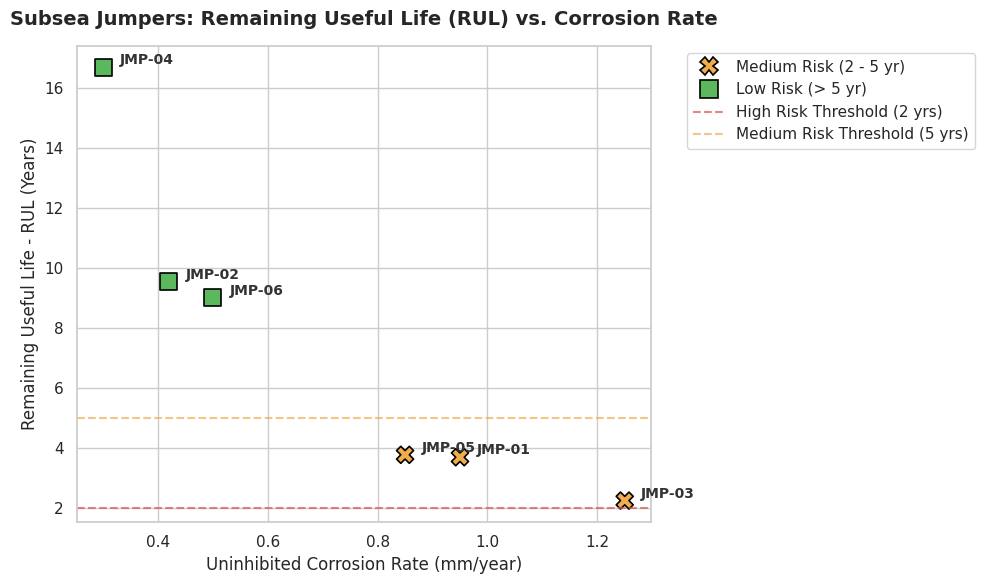

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_jumper_rul():
    # 1. Define the 6 subsea jumpers with engineering parameters
    data = {
        'Jumper_ID': ['JMP-01', 'JMP-02', 'JMP-03', 'JMP-04', 'JMP-05', 'JMP-06'],
        'Nominal_OD_inch': [8.625, 10.75, 8.625, 12.75, 10.75, 8.625],
        'Corrosion_Allowance_mm': [3.5, 4.0, 2.8, 5.0, 3.2, 4.5],
        'Corrosion_Rate_mm_yr': [0.95, 0.42, 1.25, 0.30, 0.85, 0.50]
    }

    df = pd.DataFrame(data)

    # 2. Calculate Remaining Useful Life (RUL in years)
    df['RUL_years'] = df['Corrosion_Allowance_mm'] / df['Corrosion_Rate_mm_yr']

    # 3. Assign Risk Classifications based on RUL thresholds
    # - High Risk (Critical): RUL < 2.0 years
    # - Medium Risk (Warning): 2.0 <= RUL <= 5.0 years
    # - Low Risk (Normal): RUL > 5.0 years
    def classify_risk(rul):
        if rul < 2.0:
            return 'High Risk (RUL < 2 yr)'
        elif rul <= 5.0:
            return 'Medium Risk (2 - 5 yr)'
        else:
            return 'Low Risk (> 5 yr)'

    df['Risk_Class'] = df['RUL_years'].apply(classify_risk)

    print("--- Jumper RUL & Risk Assessment Summary ---")
    print(df[['Jumper_ID', 'Corrosion_Allowance_mm', 'Corrosion_Rate_mm_yr', 'RUL_years', 'Risk_Class']].to_string(index=False))

    # 4. Create Visualization
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    # Color palette for risk categories
    palette = {
        'High Risk (RUL < 2 yr)': '#d9534f',      # Red
        'Medium Risk (2 - 5 yr)': '#f0ad4e',   # Yellow/Orange
        'Low Risk (> 5 yr)': '#5cb85c'         # Green
    }

    # Scatter plot
    ax = sns.scatterplot(
        data=df,
        x='Corrosion_Rate_mm_yr',
        y='RUL_years',
        hue='Risk_Class',
        palette=palette,
        s=150,
        style='Risk_Class',
        markers=['X', 's', 'o'],
        edgecolor='black',
        linewidth=1.2
    )

    # Annotate each jumper ID on the plot
    for i, row in df.iterrows():
        ax.text(
            row['Corrosion_Rate_mm_yr'] + 0.03,
            row['RUL_years'] + 0.1,
            row['Jumper_ID'],
            fontsize=10,
            fontweight='bold',
            color='#333333'
        )

    # Formatting plot elements
    plt.title('Subsea Jumpers: Remaining Useful Life (RUL) vs. Corrosion Rate', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Uninhibited Corrosion Rate (mm/year)', fontsize=12)
    plt.ylabel('Remaining Useful Life - RUL (Years)', fontsize=12)

    # Add horizontal threshold lines for risk zones
    plt.axhline(2.0, color='#d9534f', linestyle='--', alpha=0.7, label='High Risk Threshold (2 yrs)')
    plt.axhline(5.0, color='#f0ad4e', linestyle='--', alpha=0.7, label='Medium Risk Threshold (5 yrs)')

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
    plt.tight_layout()

    # Save figure
    plt.savefig('jumper_rul_risk_matrix.png', dpi=300)
    print("\nVisualization saved successfully as 'jumper_rul_risk_matrix.png'.")
    plt.show()

    return df

if __name__ == "__main__":
    results_df = analyze_jumper_rul()